# Two reflections at once

A second reflection `h2` held in Bragg condition is one more constraint on the
sample. The detector can sit on reflection 1 (libhkl's `double_diffraction_*`
modes) or between the two outgoing beams (`detector="between"`, the Bernina
mode), with a suggested detector distance that keeps both spots on the face.

In [1]:
import sys, os, logging, warnings
sys.path.insert(0, os.path.abspath("../src"))      # hklforge from this repository
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hklforge import Diffractometer, Geometry, ModeError, Degenerate
from hklforge.lattice import b_matrix
from hklforge.draw import draw, draw_circles
logging.getLogger("diffcalc").setLevel(logging.ERROR)
pd.set_option("display.precision", 3)
%matplotlib inline

In [2]:
psic = Geometry.builtin("psic")
si = (5.431, 5.431, 5.431, 90, 90, 90)
# the orientation used at Bernina: (1,1,1) up-ish - here simply U = identity
ub = b_matrix(*si)
d = Diffractometer(psic, ub, energy=9000, surface_hkl=(1, 1, 1))
h1, h2 = (1, 1, 1), (2, 2, 0)

## Detector on h1 (libhkl double_diffraction_vertical: mu, nu held)

In [3]:
sols = d.solve(h1, {"mu": 0, "nu": 0, "h2": h2})
print(d.plan({"mu": 0, "nu": 0, "h2": h2}).describe())
pd.DataFrame([s | {"k' separation": d.spots(s, [h1, h2])["separation"]} for s in sols])

psic: mu=0.0, nu=0.0, h2=(2, 2, 0), detector on h1  [q_x]
  1. Bragg on the detector (delta): b.k' = cos 2theta, projection (<= 2)
  2. beam in the phi frame x = R^T b from Bragg + h2: cone_points (<= 2)
  3. R from (q, x) -> (Q_lab, b); sample (eta, chi, phi): sp3 (<= 2)


,mu,eta,chi,phi,nu,delta,k' separation
0,0.0,-11.554,39.286,75.193,0.0,25.38,25.38
1,0.0,168.446,-39.286,-104.807,0.0,25.38,25.38
2,0.0,-11.554,140.714,-165.193,0.0,25.38,25.38
3,0.0,168.446,-140.714,14.807,0.0,25.38,25.38
4,0.0,-168.446,140.714,-104.807,0.0,-25.38,25.38
5,0.0,11.554,-140.714,75.193,0.0,-25.38,25.38
6,0.0,-168.446,39.286,14.807,0.0,-25.38,25.38
7,0.0,11.554,-39.286,-165.193,0.0,-25.38,25.38


## Detector between the two reflections (eta, chi held)

In [4]:
m = {"eta": 0, "chi": 0, "h2": h2}
between = d.solve(h1, m, detector="between")
print(d.plan(m, "between").describe())
pd.DataFrame([s | {k: v for k, v in d.spots(s, [h1, h2], width=77, height=77).items() if k in ("separation", "tdet_max")}
              | {"off axis 1": d.spots(s, [h1, h2])["off_axis"][0], "off axis 2": d.spots(s, [h1, h2])["off_axis"][1]}
              for s in between])

psic: eta=0.0, chi=0.0, h2=(2, 2, 0), detector on between  [between]
  1. x = R^T b from Bragg for h1 and h2: cone_points (<= 2)
  2. sample (mu, phi) from R x = b: sp2 (<= 2)
  3. detector (nu, delta) on the bisector of k'1 and k'2: sp2 (<= 2)


,mu,eta,chi,phi,nu,delta,separation,tdet_max,off axis 1,off axis 2
0,-172.714,0.0,0.0,-113.799,169.639,-149.054,25.38,173.374,12.69,12.69
1,-172.714,0.0,0.0,-113.799,-10.361,-30.946,25.38,173.374,12.69,12.69
2,-7.286,0.0,0.0,66.201,-169.639,149.054,25.38,173.374,12.69,12.69
3,-7.286,0.0,0.0,66.201,10.361,30.946,25.38,173.374,12.69,12.69
4,-172.714,0.0,0.0,23.799,169.639,149.054,25.38,173.374,12.69,12.69
5,-172.714,0.0,0.0,23.799,-10.361,30.946,25.38,173.374,12.69,12.69
6,-7.286,0.0,0.0,-156.201,-169.639,-149.054,25.38,173.374,12.69,12.69
7,-7.286,0.0,0.0,-156.201,10.361,-30.946,25.38,173.374,12.69,12.69


`tdet_max` is the largest sample-detector distance (mm for a 77 × 77 mm face) that keeps both
spots within 90 % of the half sizes. Both reflections are the same angle off the detector axis.

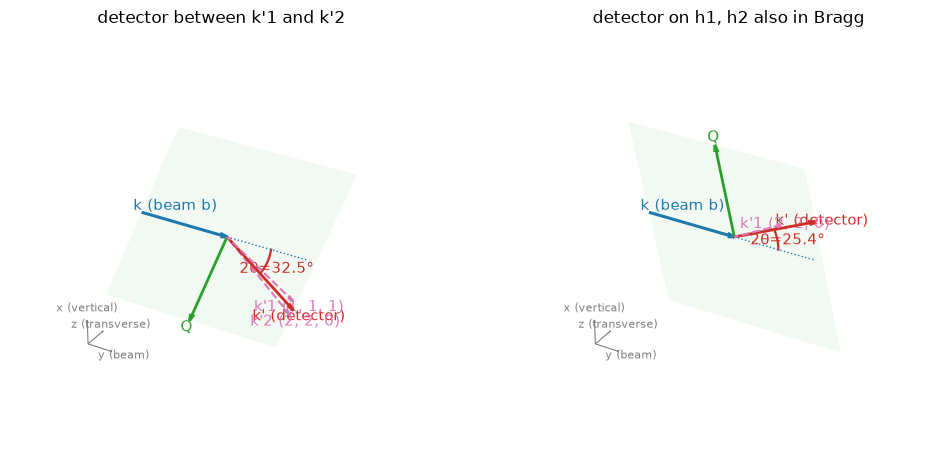

In [5]:
s = between[0]
fig = plt.figure(figsize=(12, 5.5))
draw(d, s, show=("ttheta",), hkls=[h1, h2], ax=fig.add_subplot(1, 2, 1, projection="3d"),
     title="detector between k'1 and k'2")
draw(d, sols[0], show=("ttheta",), hkls=[h2], ax=fig.add_subplot(1, 2, 2, projection="3d"),
     title="detector on h1, h2 also in Bragg");

## Both reflections really are in Bragg condition
|k b + R UB h| = |k| for each, at every solution:

In [6]:
for name, ss in (("on h1", sols), ("between", between)):
    err = max(abs(np.linalg.norm(d.k * np.asarray(psic.beam) + psic.sample_matrix(s) @ ub @ np.asarray(h)) - d.k)
              for s in ss for h in (h1, h2))
    print(f"{name}: {len(ss)} solutions, worst Ewald-sphere error {err:.1e} 1/A")

on h1: 8 solutions, worst Ewald-sphere error 8.9e-16 1/A
between: 8 solutions, worst Ewald-sphere error 8.9e-16 1/A


## Against the Bernina reference solver
`dev/reference/bernina_two_reflections.py` (scan + root polish, checked against diffcalc and
libhkl) - if bernina-scripts is available:

In [7]:
try:
    sys.path[:0] = [os.path.expanduser("~/mypy/bernina-scripts"), os.path.abspath("../dev/reference")]
    import bernina_two_reflections as REF
    from bernina_prep import diffraction as BD
    ubc = BD.build_ubcalc("si", *si, ["(1,1,1) > (1,0,0)", "(1,1,-1) > (0,1,0)"], "(1,1,1)", frame="swissfel")
    import itertools, time
    dd = Diffractometer(psic, ubc.UB, energy=9000)
    rows = []
    for pair in itertools.combinations(["mu", "eta", "chi", "phi"], 2):
        fixed = {n: 0.0 for n in pair}
        t = time.perf_counter()
        try:
            df = REF.solve_two_reflections(ubc, h1, h2, 9000, fixed)
            ref = [{**{n: df[c][n] for n in ("mu", "eta", "chi", "phi")}, "nu": df[c]["gamma"], "delta": df[c]["delta"]} for c in df.columns]
        except ValueError:
            ref = []
        t_ref = time.perf_counter() - t
        t = time.perf_counter()
        try:
            mine = dd.solve(h1, fixed | {"h2": h2}, detector="between"); note = ""
        except Degenerate as e:
            mine, note = [], "continuum (chi = 0: eta and phi on one axis)"
        t_mine = time.perf_counter() - t
        same_ = lambda a, b: all(abs((a[n] - b[n] + 180) % 360 - 180) < 1e-4 for n in a)
        ident = all(any(same_(r, m) for m in mine) for r in ref) and all(any(same_(m, r) for r in ref) for m in mine)
        rows.append({"held": pair, "reference": len(ref), "hklforge": len(mine), "identical": ident,
                     "reference ms": 1e3 * t_ref, "hklforge ms": 1e3 * t_mine, "note": note})
    display(pd.DataFrame(rows))
except ImportError as e:
    print("bernina-scripts not available:", e)

,held,reference,hklforge,identical,reference ms,hklforge ms,note
0,"(mu, eta)",0,0,True,36.719,0.466,
1,"(mu, chi)",0,0,True,46.547,0.496,continuum (chi = 0: eta and phi on one axis)
2,"(mu, phi)",8,8,True,98.024,3.935,
3,"(eta, chi)",8,8,True,74.499,4.020,
4,"(eta, phi)",8,8,True,94.917,3.899,
5,"(chi, phi)",8,8,True,85.382,3.595,
